# Phát hiện ngoại biên bằng DBSCAN

DBSCAN tìm các vùng có mật độ đủ cao và nối các vùng đó thành cụm. Với bán kính $\varepsilon$, lân cận của điểm $x$ là

$$
N_\varepsilon(x)=\{y\mid \lVert x-y\rVert_2\le\varepsilon\}.
$$

Một **điểm lõi** thỏa $|N_\varepsilon(x)|\ge m$, với $m$ là `min_samples` và số đếm bao gồm chính $x$. Các điểm lõi liên thông qua lân cận tạo phần lõi của cụm. **Điểm biên** ở trong lân cận của một điểm lõi nhưng chưa đủ mật độ để tự làm lõi. Những điểm còn lại nhận nhãn nhiễu `-1`.

Đề tài dùng DBSCAN để tìm khách hàng nằm ngoài các vùng mật độ cao. Một cụm chính kèm nhiễu vẫn có thể phù hợp với mục tiêu này. Nhóm đánh giá sẽ đối chiếu nhãn `-1` với hồ sơ giao dịch để diễn giải ý nghĩa (xem đó là khách sỉ B2B hay khách mua bất thường).

In [1]:
import sys
from pathlib import Path

working_dir = Path.cwd()
for directory in (working_dir, *working_dir.parents):
    if (directory / "clustering" / "models.py").is_file():
        if str(directory) not in sys.path:
            sys.path.insert(0, str(directory))
        break
else:
    raise RuntimeError("Hãy mở notebook với kernel chạy trong thư mục repo.")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

from clustering.models import (
    RESULTS_DIR,
    fit_dbscan,
    load_scaled_data,
    run_grid_search,
    save_cluster_labels,
    save_tuning_results,
)

REVIEW_PARAMS = None  # Có thể điền một cặp (eps, min_samples) đã xem xét.

customer_ids, X = load_scaled_data()
results_dir = RESULTS_DIR

Đã đọc 5,852 khách hàng từ data/processed/X_scaled.csv


## Dò bán kính từ đồ thị k-distance

Dựng đường cong k-distance cho 3 mức `min_samples` ($m$) trên không gian $d = 8$ đặc trưng:
- `m = 5`: giá trị mặc định của `scikit-learn`.
- `m = 9` ($d + 1$): ngưỡng tối thiểu hay dùng cho dữ liệu nhiều chiều.
- `m = 16` ($2d$): mật độ chặt hơn, lọc nhiễu mạnh hơn.

Với từng $m$, tính khoảng cách từ mỗi khách tới láng giềng thứ $m$ (tính cả chính nó) rồi sắp xếp tăng dần. Đó là bán kính $\varepsilon$ tối thiểu để điểm đó thành điểm lõi. Đường cong thường thoải ở vùng khách đông và dựng đứng ở phần đuôi ngoại biên.

Để tìm điểm gãy (`knees[m]`), chuẩn hóa cả hai trục về $[0, 1]$ rồi lấy vị trí lệch xa nhất dưới dây nối hai đầu (`argmax(progress - y_norm)`). Phần 2% đuôi cực trị được tạm bỏ khi ước lượng điểm gãy để vài khách sỉ quá xa không ép dẹt phần đường cong phía trước; bước sau vẫn quét lưới hai phía quanh `knees[m]`.

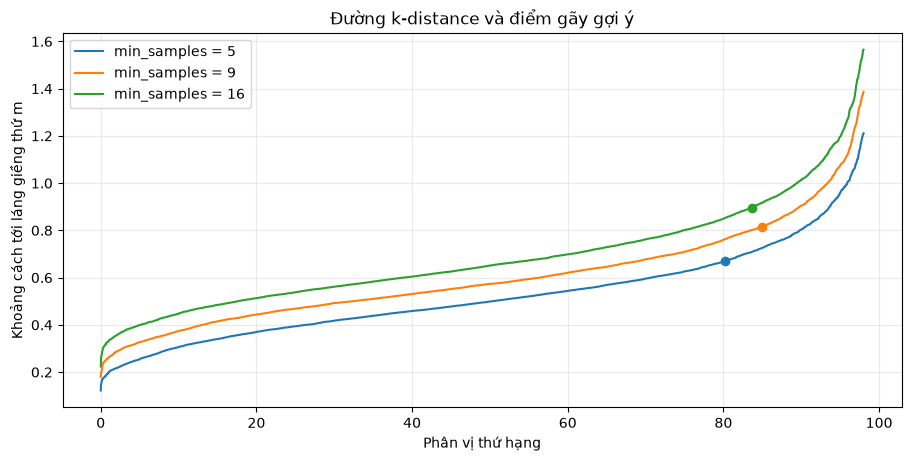

In [2]:
MIN_SAMPLES = [m for m in (5, X.shape[1] + 1, 2 * X.shape[1]) if m <= len(X)]
if not MIN_SAMPLES:
    raise ValueError("Cần ít nhất năm khách để thử cấu hình DBSCAN.")

knees = {}
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for m in MIN_SAMPLES:
    neighbors = NearestNeighbors(n_neighbors=m).fit(X)
    distances, _ = neighbors.kneighbors(X)
    ordered = np.sort(distances[:, -1])
    curve = ordered[:int(np.ceil(0.98 * len(ordered)))]
    rank = np.linspace(0, (len(curve) - 1) / (len(ordered) - 1), len(curve))
    progress = np.linspace(0, 1, len(curve))
    span = max(curve[-1] - curve[0], np.finfo(float).eps)
    knee_index = int(np.argmax(progress - (curve - curve[0]) / span))

    positive = ordered[ordered > 0]
    smallest_positive = positive[0] if positive.size else np.finfo(float).eps
    knees[m] = float(max(curve[knee_index], smallest_positive))
    line, = ax.plot(100 * rank, curve, label=f"min_samples = {m}")
    ax.scatter(100 * rank[knee_index], knees[m], color=line.get_color())
ax.set(xlabel="Phân vị thứ hạng", ylabel="Khoảng cách tới láng giềng thứ m",
       title="Đường k-distance và điểm gãy gợi ý")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## So sánh số cụm và tỷ lệ nhiễu quanh điểm gãy

Vì $\varepsilon_{\text{knee}}$ mới là điểm neo hình học ban đầu, với mỗi $m \in \{5, 9, 16\}$ ta quét thêm 5 mức bán kính trong khoảng $\pm 15\%$ quanh điểm gãy:

$$
\varepsilon \in \{0.85,\; 0.90,\; 1.00,\; 1.10,\; 1.15\} \times \varepsilon_{\text{knee}}
$$

Quét lưới 15 cấu hình này để kiểm tra độ nhạy của số cụm và tỷ lệ nhiễu khi dịch nhẹ bán kính, đồng thời lấy dữ liệu ở 3 mốc `0.90x`, `1.00x`, `1.10x` cho bước chọn cấu hình cuối.

Tỷ lệ điểm nhiễu được tính bằng:

$$
\mathrm{noise\_ratio}=\frac{\#\{i\mid \mathrm{label}_i=-1\}}{n}.
$$

Các chỉ số nội bộ chỉ tính trên tập khách vào cụm (`ignore_noise=True`) khi có ít nhất 2 cụm, nên cần đọc kèm `noise_ratio` và `min_cluster_size` để tránh nhầm với trường hợp 1 cụm lớn kèm vài cụm nhỏ 2-5 điểm.

,min_samples,eps,eps_factor,n_clusters,noise_ratio,min_cluster_size,silhouette
0,5,0.5681,0.85,10,0.2165,2,-0.2582
1,5,0.6015,0.90,9,0.1728,2,-0.2750
2,5,0.6684,1.00,1,0.1155,5176,NaN
3,5,0.7352,1.10,2,0.0776,5,0.3227
4,5,0.7686,1.15,4,0.0639,4,0.1934
5,9,0.6927,0.85,1,0.1336,5070,NaN
6,9,0.7334,0.90,3,0.1027,8,0.0104
7,9,0.8149,1.00,1,0.0653,5470,NaN
8,9,0.8964,1.10,1,0.0451,5588,NaN
9,9,0.9371,1.15,1,0.0384,5627,NaN


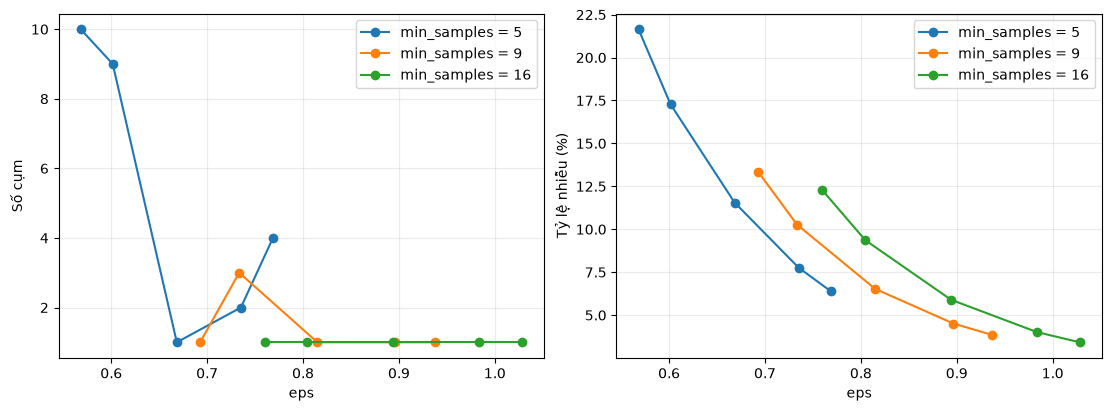

In [3]:
EPS_FACTORS = [0.85, 0.90, 1.0, 1.10, 1.15] # +- 15% heuristic quanh knees để search optimal
tables = []
for m, knee in knees.items():
    scores = run_grid_search(
        X,
        model_builder=DBSCAN,
        param_grid={"eps": [factor * knee for factor in EPS_FACTORS], "min_samples": [m]},
        ignore_noise=True,
    )
    tables.append(scores.assign(eps_factor=EPS_FACTORS, knee_eps=knee))
tuning = pd.concat(tables, ignore_index=True)
display(tuning[["min_samples", "eps", "eps_factor", "n_clusters",
                "noise_ratio", "min_cluster_size", "silhouette"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for m, scores in tuning.groupby("min_samples"):
    label = f"min_samples = {m}"
    axes[0].plot(scores["eps"], scores["n_clusters"], marker="o", label=label)
    axes[1].plot(scores["eps"], scores["noise_ratio"] * 100, marker="o", label=label)
for ax, title in zip(axes, ["Số cụm", "Tỷ lệ nhiễu (%)"]):
    ax.set(xlabel="eps", ylabel=title)
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Chọn ứng viên theo độ ổn định cụm và tập nhiễu

Do tại điểm gãy dữ liệu tạo 1 cụm chính kèm nhiễu (`-1`), các chỉ số nội cụm như Silhouette là `NaN`. Cả 3 mức $m \in \{5, 9, 16\}$ tại điểm gãy được xếp hạng theo 3 tiêu chí:
1. `cluster_stable`: số cụm giữ nguyên khi dịch $\varepsilon$ trong khoảng $\pm 10\%$ (`0.90x`, `1.00x`, `1.10x`), tránh cấu hình dễ vỡ thành cụm nhỏ.
2. `noise_in_1_10_pct`: tỷ lệ nhiễu nằm trong khoảng 1%-10%, đủ tách ngoại biên mà không gán nhầm quá nhiều khách thường.
3. `noise_overlap`: tỷ số số điểm nhiễu ở $1.10\varepsilon$ trên $0.90\varepsilon$ (tập nhiễu ở bán kính lớn là tập con của bán kính nhỏ, tỷ số cao hơn nghĩa là tập ngoại biên ổn định hơn).

Có thể gán trực tiếp một cặp `(eps, min_samples)` vào `REVIEW_PARAMS` ở đầu notebook nếu muốn chọn thủ công.

In [4]:
candidates = []
for m, scores in tuning.groupby("min_samples"):
    around_knee = scores.set_index("eps_factor")
    center = around_knee.loc[1.0]
    if center["n_clusters"] > 0 and center["n_noise"] > 0:
        stability = around_knee.loc[1.10, "n_noise"] / around_knee.loc[0.90, "n_noise"]
        cluster_counts = around_knee.loc[[0.90, 1.0, 1.10], "n_clusters"]
        cluster_stable = bool(cluster_counts.nunique() == 1)
        noise_ratio = float(center["noise_ratio"])
        candidates.append({
            "min_samples": int(m),
            "eps": float(center["eps"]),
            "n_clusters": int(center["n_clusters"]),
            "noise_ratio": noise_ratio,
            "cluster_stable": cluster_stable,
            "noise_in_1_10_pct": bool(0.01 <= noise_ratio <= 0.10),
            "noise_overlap": float(stability),
        })

if REVIEW_PARAMS is not None:
    requested_eps, best_m = REVIEW_PARAMS
    tested_eps = tuning.loc[
        tuning["min_samples"].eq(best_m)
        & np.isclose(tuning["eps"], requested_eps, rtol=0.001, atol=0),
        "eps",
    ]
    if tested_eps.empty:
        raise ValueError("REVIEW_PARAMS phải là một cặp (eps, min_samples) trong bảng.")
    best_eps = float(tested_eps.iloc[0])
elif candidates:
    ranked = pd.DataFrame(candidates).sort_values(
        ["cluster_stable", "noise_in_1_10_pct", "noise_overlap"],
        ascending=[False, False, False],
    )
    display(ranked.round(4))
    best_eps, best_m = float(ranked.iloc[0]["eps"]), int(ranked.iloc[0]["min_samples"])
else:
    eligible = tuning[(tuning["n_clusters"] > 0) & (tuning["n_noise"] > 0)]
    pool = eligible if not eligible.empty else tuning
    closest = (pool["eps_factor"] - 1).abs().idxmin()
    best_eps, best_m = float(pool.loc[closest, "eps"]), int(pool.loc[closest, "min_samples"])
    if eligible.empty:
        print("Lưới tham số chưa cho cấu hình có cả cụm và nhiễu.")

final_model, final_labels = fit_dbscan(X, eps=best_eps, min_samples=best_m)
tuning["selected"] = tuning["min_samples"].eq(best_m) & tuning["eps"].eq(best_eps)
print(f"Cấu hình chọn: eps={best_eps:.6g}, min_samples={best_m}, nhiễu={(final_labels == -1).mean():.2%} ({int((final_labels == -1).sum())} khách).")
display(pd.Series(final_labels, name="Số khách").value_counts().sort_index())
save_tuning_results(tuning, "tuning_dbscan.csv", results_dir)
_ = save_cluster_labels(customer_ids, "dbscan", final_labels, results_dir / "labels.csv")

,min_samples,eps,n_clusters,noise_ratio,cluster_stable,noise_in_1_10_pct,noise_overlap
2,16,0.8940,1,0.0590,True,True,0.4288
1,9,0.8149,1,0.0653,False,True,0.4393
0,5,0.6684,1,0.1155,False,False,0.4491


Cấu hình chọn: eps=0.893989, min_samples=16, nhiễu=5.90% (345 khách).


Số khách
-1     345
 0    5507
Name: count, dtype: int64

[SAVED] Đã lưu bảng tinh chỉnh -> clustering/results/tuning_dbscan.csv
[SAVED] Đã cập nhật cột 'dbscan' -> clustering/results/labels.csv
